# Bài 2 (Trang 30) - Dữ liệu môi trường tb_tracking
## Câu 4: d) Vẽ đồ thị phân tán CO, độ ẩm, nhiệt độ theo minutes

**Sinh viên:** Trần Đình Võ - **MSSV:** 6451071088

In [1]:
HO_TEN = "Trần Đình Võ"
MSSV = "6451071088"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

Họ tên: Trần Đình Võ - MSSV: 6451071088


### Import thư viện và đọc dữ liệu

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

df = pd.read_excel("../Dataset/tb_tracking.xlsx", header=None)

### Các bước xử lý của câu 1 → 3 (chuẩn bị dữ liệu)

In [3]:
df.columns = ["id", "device_id", "co_level", "humidity", "temperature", "time"]
df["time"] = pd.to_datetime(df["time"])

df = df[df["time"] >= "2018-01-03"].reset_index(drop=True)

df["minutes"] = df["time"].dt.hour * 60 + df["time"].dt.minute

### Câu 4: d) Vẽ đồ thị phân tán CO, độ ẩm, nhiệt độ theo minutes

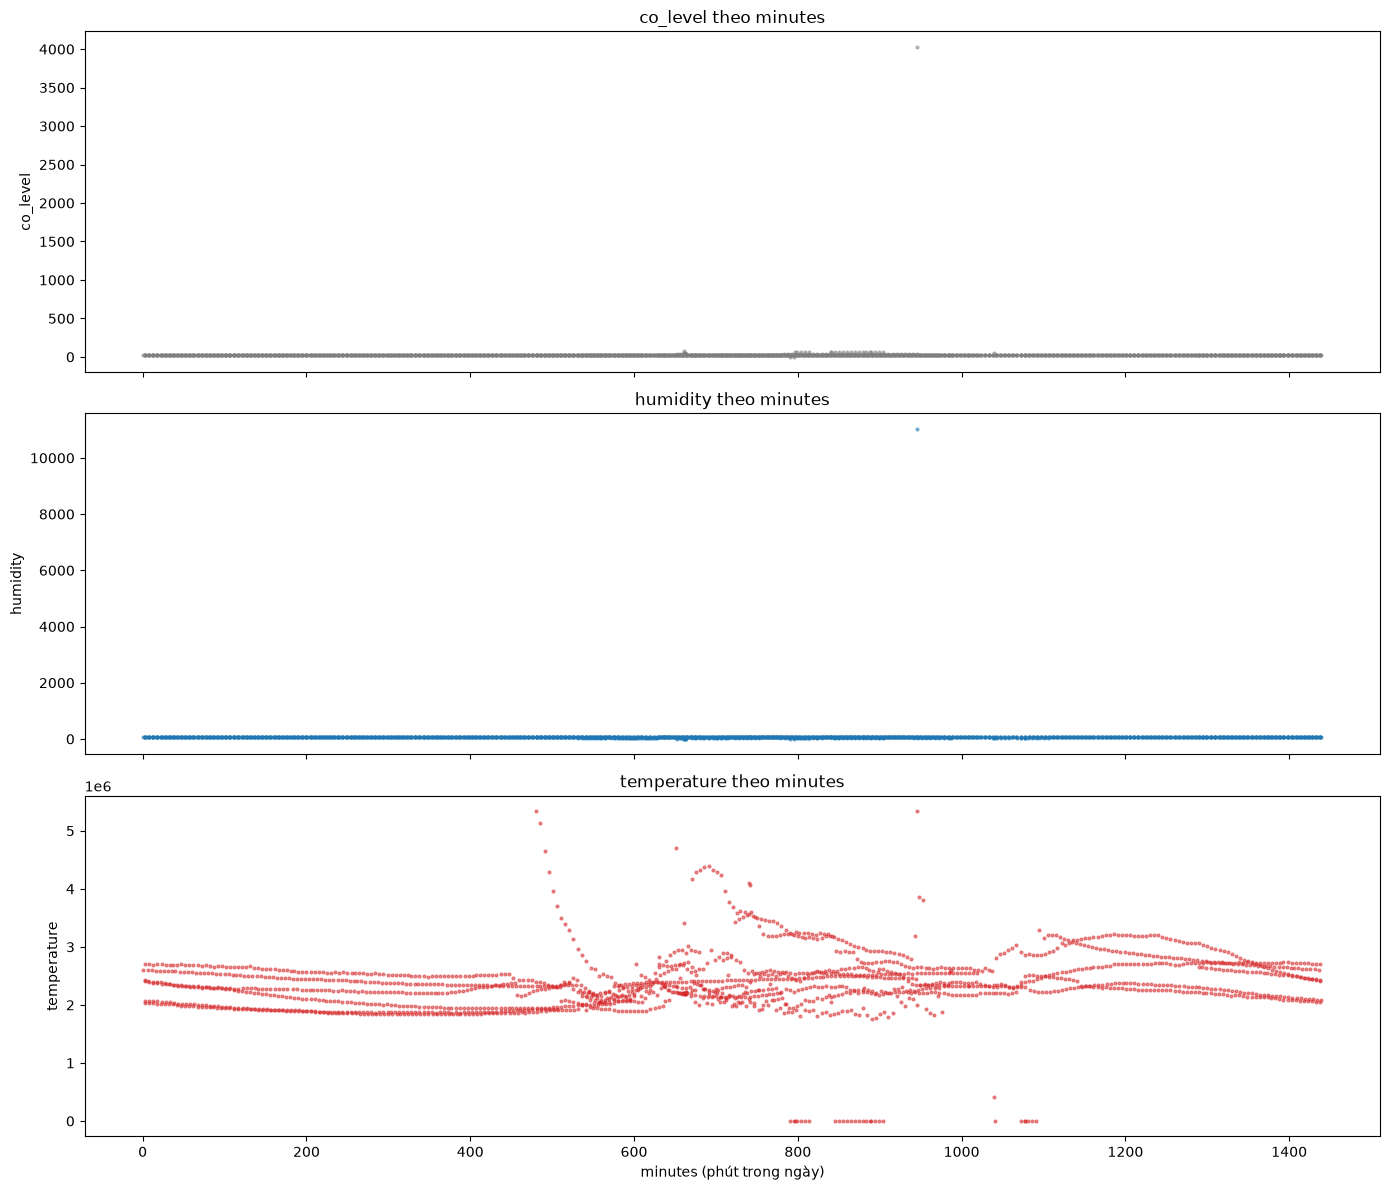

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
for ax, col, color in zip(axes, ["co_level", "humidity", "temperature"], ["tab:gray", "tab:blue", "tab:red"]):
    ax.scatter(df["minutes"], df[col], s=4, alpha=0.5, color=color)
    ax.set_ylabel(col)
    ax.set_title(f"{col} theo minutes")
axes[-1].set_xlabel("minutes (phút trong ngày)")
plt.tight_layout()
plt.show()

### Nhận xét
- Các biểu đồ phân tán cho thấy sự thay đổi của nồng độ CO, độ ẩm và nhiệt độ theo thời điểm đo trong ngày; dữ liệu chủ yếu tập trung vào khung giờ làm việc của nhà xưởng.
- Có một số điểm nằm tách biệt (giá trị bằng 0 hoặc rất lớn) là nhiễu/ngoại lai do thiết bị đo.